## 1. Import Required Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# PyTorch imports
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, TensorDataset

# Scikit-learn imports
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    accuracy_score, 
    classification_report, 
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score
)

# Set style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 8)

print("✅ Libraries imported successfully!")
print(f"PyTorch version: {torch.__version__}")
print(f"NumPy version: {np.__version__}")
print(f"Pandas version: {pd.__version__}")

✅ Libraries imported successfully!
PyTorch version: 2.5.1+cu121
NumPy version: 1.26.4
Pandas version: 2.1.4


## 2. Check GPU Availability

In [2]:
# Check GPU availability
print("Checking GPU availability...")
print("="*60)

if torch.cuda.is_available():
    device = torch.device('cuda')
    print("✅ GPU FOUND!")
    print(f"   Device: {torch.cuda.get_device_name(0)}")
    print(f"   Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
    print(f"   CUDA Version: {torch.version.cuda}")
else:
    device = torch.device('cpu')
    print("⚠️  GPU not available, using CPU")

print("="*60)
print(f"Training device: {device}")
print("="*60)

Checking GPU availability...
✅ GPU FOUND!
   Device: NVIDIA GeForce RTX 4060 Laptop GPU
   Memory: 8.59 GB
   CUDA Version: 12.1
Training device: cuda


## 3. Define EEG Conformer Architecture

In [3]:
class PatchEmbedding(nn.Module):
    """Convolutional Patch Embedding for EEG signals"""
    def __init__(self, n_channels=14, n_samples=128, embed_dim=256, patch_size=16):
        super(PatchEmbedding, self).__init__()
        
        # Convolutional layers for local feature extraction
        self.conv1 = nn.Conv2d(1, 32, kernel_size=(1, 25), padding='same')
        self.bn1 = nn.BatchNorm2d(32)
        
        self.conv2 = nn.Conv2d(32, 64, kernel_size=(n_channels, 1))
        self.bn2 = nn.BatchNorm2d(64)
        
        self.pool = nn.AvgPool2d((1, 4))
        self.dropout = nn.Dropout(0.5)
        
        # Calculate output size after convolutions
        self.seq_len = n_samples // 4  # After pooling
        
        # Project to embedding dimension
        self.projection = nn.Linear(64, embed_dim)
        
    def forward(self, x):
        # x shape: (batch, 1, n_channels, n_samples)
        x = F.elu(self.bn1(self.conv1(x)))
        x = F.elu(self.bn2(self.conv2(x)))
        x = self.pool(x)
        x = self.dropout(x)
        
        # Reshape: (batch, 64, 1, seq_len) -> (batch, seq_len, 64)
        x = x.squeeze(2).permute(0, 2, 1)
        
        # Project to embedding dimension
        x = self.projection(x)
        
        return x


class MultiHeadSelfAttention(nn.Module):
    """Multi-Head Self-Attention mechanism"""
    def __init__(self, embed_dim=256, num_heads=8, dropout=0.5):
        super(MultiHeadSelfAttention, self).__init__()
        
        self.embed_dim = embed_dim
        self.num_heads = num_heads
        self.head_dim = embed_dim // num_heads
        
        assert self.head_dim * num_heads == embed_dim, "embed_dim must be divisible by num_heads"
        
        self.qkv = nn.Linear(embed_dim, embed_dim * 3)
        self.attn_drop = nn.Dropout(dropout)
        self.proj = nn.Linear(embed_dim, embed_dim)
        self.proj_drop = nn.Dropout(dropout)
        
    def forward(self, x):
        batch_size, seq_len, embed_dim = x.shape
        
        # Generate Q, K, V
        qkv = self.qkv(x).reshape(batch_size, seq_len, 3, self.num_heads, self.head_dim)
        qkv = qkv.permute(2, 0, 3, 1, 4)  # (3, batch, num_heads, seq_len, head_dim)
        q, k, v = qkv[0], qkv[1], qkv[2]
        
        # Scaled dot-product attention
        attn = (q @ k.transpose(-2, -1)) * (self.head_dim ** -0.5)
        attn = F.softmax(attn, dim=-1)
        attn = self.attn_drop(attn)
        
        # Apply attention to values
        x = (attn @ v).transpose(1, 2).reshape(batch_size, seq_len, embed_dim)
        
        # Output projection
        x = self.proj(x)
        x = self.proj_drop(x)
        
        return x


class FeedForward(nn.Module):
    """Feed-Forward Network"""
    def __init__(self, embed_dim=256, hidden_dim=1024, dropout=0.5):
        super(FeedForward, self).__init__()
        
        self.fc1 = nn.Linear(embed_dim, hidden_dim)
        self.fc2 = nn.Linear(hidden_dim, embed_dim)
        self.dropout = nn.Dropout(dropout)
        
    def forward(self, x):
        x = F.gelu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        x = self.dropout(x)
        return x


class ConformerBlock(nn.Module):
    """Conformer Block: Self-Attention + Feed-Forward with residual connections"""
    def __init__(self, embed_dim=256, num_heads=8, hidden_dim=1024, dropout=0.5):
        super(ConformerBlock, self).__init__()
        
        self.ln1 = nn.LayerNorm(embed_dim)
        self.attn = MultiHeadSelfAttention(embed_dim, num_heads, dropout)
        
        self.ln2 = nn.LayerNorm(embed_dim)
        self.ffn = FeedForward(embed_dim, hidden_dim, dropout)
        
    def forward(self, x):
        # Self-attention with residual
        x = x + self.attn(self.ln1(x))
        
        # Feed-forward with residual
        x = x + self.ffn(self.ln2(x))
        
        return x


class EEGConformer(nn.Module):
    """
    EEG Conformer: CNN + Transformer for EEG Classification
    
    Combines convolutional layers for local feature extraction with
    transformer blocks for capturing long-range temporal dependencies.
    
    Parameters:
        n_classes (int): Number of output classes
        n_channels (int): Number of EEG channels
        n_samples (int): Number of time samples
        embed_dim (int): Embedding dimension
        num_heads (int): Number of attention heads
        num_layers (int): Number of Conformer blocks
        hidden_dim (int): Hidden dimension in feed-forward network
        dropout (float): Dropout rate
    """
    def __init__(self, n_classes=4, n_channels=14, n_samples=128, 
                 embed_dim=256, num_heads=8, num_layers=4, 
                 hidden_dim=1024, dropout=0.5):
        super(EEGConformer, self).__init__()
        
        self.n_classes = n_classes
        self.n_channels = n_channels
        self.n_samples = n_samples
        
        # Patch embedding (CNN feature extraction)
        self.patch_embed = PatchEmbedding(n_channels, n_samples, embed_dim)
        
        # Positional encoding
        self.pos_embed = nn.Parameter(torch.zeros(1, n_samples // 4, embed_dim))
        self.pos_drop = nn.Dropout(dropout)
        
        # Conformer blocks
        self.conformer_blocks = nn.ModuleList([
            ConformerBlock(embed_dim, num_heads, hidden_dim, dropout)
            for _ in range(num_layers)
        ])
        
        # Layer normalization
        self.ln = nn.LayerNorm(embed_dim)
        
        # Classification head
        self.classifier = nn.Sequential(
            nn.Linear(embed_dim, hidden_dim // 2),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim // 2, n_classes)
        )
        
        # Initialize positional embeddings
        nn.init.trunc_normal_(self.pos_embed, std=0.02)
        
    def forward(self, x):
        # x shape: (batch, 1, n_channels, n_samples)
        
        # Patch embedding
        x = self.patch_embed(x)  # (batch, seq_len, embed_dim)
        
        # Add positional encoding
        x = x + self.pos_embed
        x = self.pos_drop(x)
        
        # Apply Conformer blocks
        for block in self.conformer_blocks:
            x = block(x)
        
        # Layer normalization
        x = self.ln(x)
        
        # Global average pooling
        x = x.mean(dim=1)  # (batch, embed_dim)
        
        # Classification
        x = self.classifier(x)
        
        return x


# Test model initialization
print("Testing EEG Conformer architecture...")
model_test = EEGConformer(n_classes=4, n_channels=14, n_samples=128,
                          embed_dim=256, num_heads=8, num_layers=4)
test_input = torch.randn(2, 1, 14, 128)
test_output = model_test(test_input)
print(f"✅ EEG Conformer initialized successfully!")
print(f"   Input shape: {test_input.shape}")
print(f"   Output shape: {test_output.shape}")
print(f"   Number of parameters: {sum(p.numel() for p in model_test.parameters()):,}")
print(f"   Trainable parameters: {sum(p.numel() for p in model_test.parameters() if p.requires_grad):,}")

Testing EEG Conformer architecture...
✅ EEG Conformer initialized successfully!
   Input shape: torch.Size([2, 1, 14, 128])
   Output shape: torch.Size([2, 4])
   Number of parameters: 3,347,780
   Trainable parameters: 3,347,780
✅ EEG Conformer initialized successfully!
   Input shape: torch.Size([2, 1, 14, 128])
   Output shape: torch.Size([2, 4])
   Number of parameters: 3,347,780
   Trainable parameters: 3,347,780


## 4. Load Pre-saved Fold Data

In [4]:
# Define data directory
FOLD_DIR = Path("trainfold")
n_splits = 5

# Class mapping
class_names = ['Apple', 'Car', 'Flower', 'Human Face']
class_map = {1: 'Apple', 2: 'Car', 3: 'Flower', 4: 'Human Face'}

print("="*60)
print("LOADING PRE-SAVED FOLD DATA")
print("="*60)
print(f"Fold directory: {FOLD_DIR}")
print(f"Number of folds: {n_splits}")

# Verify folds exist
for fold_num in range(1, n_splits + 1):
    fold_path = FOLD_DIR / f"fold_{fold_num}"
    train_file = fold_path / "train.csv"
    test_file = fold_path / "test.csv"
    
    if train_file.exists() and test_file.exists():
        train_df = pd.read_csv(train_file)
        test_df = pd.read_csv(test_file)
        print(f"\n✅ Fold {fold_num}:")
        print(f"   Train: {len(train_df)} samples")
        print(f"   Test:  {len(test_df)} samples")
    else:
        print(f"\n❌ Fold {fold_num}: Files not found!")

print("\n" + "="*60)
print("All folds verified successfully!")
print("="*60)

LOADING PRE-SAVED FOLD DATA
Fold directory: trainfold
Number of folds: 5

✅ Fold 1:
   Train: 2889 samples
   Test:  723 samples

✅ Fold 1:
   Train: 2889 samples
   Test:  723 samples

✅ Fold 2:
   Train: 2889 samples
   Test:  723 samples

✅ Fold 2:
   Train: 2889 samples
   Test:  723 samples

✅ Fold 3:
   Train: 2890 samples
   Test:  722 samples

✅ Fold 3:
   Train: 2890 samples
   Test:  722 samples

✅ Fold 4:
   Train: 2890 samples
   Test:  722 samples

✅ Fold 4:
   Train: 2890 samples
   Test:  722 samples

✅ Fold 5:
   Train: 2890 samples
   Test:  722 samples

All folds verified successfully!

✅ Fold 5:
   Train: 2890 samples
   Test:  722 samples

All folds verified successfully!


## 5. Data Preprocessing Functions

In [5]:
def prepare_conformer_data(df, scaler=None, fit_scaler=True):
    """
    Prepare data for EEG Conformer input
    
    Parameters:
        df: DataFrame with features and Class column
        scaler: StandardScaler object (optional)
        fit_scaler: Whether to fit the scaler (True for train, False for test)
    
    Returns:
        X_reshaped: Data in shape (n_samples, 1, n_channels, n_timepoints)
        y: Labels (0-indexed)
        scaler: Fitted scaler object
    """
    # Separate features and labels
    X = df.iloc[:, :-1].values  # All columns except last (Class)
    y = df.iloc[:, -1].values   # Last column (Class)
    
    # Encode labels to 0-based indexing (1,2,3,4 -> 0,1,2,3)
    le = LabelEncoder()
    y_encoded = le.fit_transform(y)
    
    # Standardize features
    if scaler is None:
        scaler = StandardScaler()
    
    if fit_scaler:
        X_scaled = scaler.fit_transform(X)
    else:
        X_scaled = scaler.transform(X)
    
    # Reshape for Conformer: (n_samples, n_features) -> (n_samples, 1, n_channels, n_timepoints)
    # Features: 14 channels × 128 timepoints = 1792 features
    n_samples = X_scaled.shape[0]
    n_channels = 14
    n_timepoints = 128
    
    X_reshaped = X_scaled.reshape(n_samples, n_channels, n_timepoints)
    X_reshaped = np.expand_dims(X_reshaped, axis=1)  # Add channel dimension
    
    return X_reshaped, y_encoded, scaler

# Test the function
print("Testing data preparation function...")
test_df = pd.read_csv(FOLD_DIR / "fold_1" / "train.csv")
X_test, y_test, scaler_test = prepare_conformer_data(test_df)
print(f"✅ Data preparation successful!")
print(f"   Input shape: {X_test.shape}")
print(f"   Expected: (n_samples, 1, 14, 128)")
print(f"   Labels shape: {y_test.shape}")
print(f"   Unique labels: {np.unique(y_test)}")
print(f"   Label range: [{y_test.min()}, {y_test.max()}]")

Testing data preparation function...
✅ Data preparation successful!
   Input shape: (2889, 1, 14, 128)
   Expected: (n_samples, 1, 14, 128)
   Labels shape: (2889,)
   Unique labels: [0 1 2 3]
   Label range: [0, 3]
✅ Data preparation successful!
   Input shape: (2889, 1, 14, 128)
   Expected: (n_samples, 1, 14, 128)
   Labels shape: (2889,)
   Unique labels: [0 1 2 3]
   Label range: [0, 3]


## 6. Training Functions

In [6]:
def train_epoch(model, train_loader, criterion, optimizer, device):
    """Train for one epoch"""
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        
        # Zero the parameter gradients
        optimizer.zero_grad()
        
        # Forward
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        
        # Backward + optimize
        loss.backward()
        optimizer.step()
        
        # Statistics
        running_loss += loss.item()
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
    
    epoch_loss = running_loss / len(train_loader)
    epoch_acc = 100 * correct / total
    
    return epoch_loss, epoch_acc

def evaluate(model, test_loader, criterion, device):
    """Evaluate the model"""
    model.eval()
    running_loss = 0.0
    all_preds = []
    all_labels = []
    
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            
            # Forward
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            
            # Statistics
            running_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            
            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
    
    epoch_loss = running_loss / len(test_loader)
    all_preds = np.array(all_preds)
    all_labels = np.array(all_labels)
    
    # Calculate metrics
    accuracy = accuracy_score(all_labels, all_preds)
    f1_macro = f1_score(all_labels, all_preds, average='macro')
    f1_weighted = f1_score(all_labels, all_preds, average='weighted')
    precision = precision_score(all_labels, all_preds, average='macro')
    recall = recall_score(all_labels, all_preds, average='macro')
    cm = confusion_matrix(all_labels, all_preds)
    
    return {
        'loss': epoch_loss,
        'accuracy': accuracy,
        'f1_macro': f1_macro,
        'f1_weighted': f1_weighted,
        'precision': precision,
        'recall': recall,
        'confusion_matrix': cm,
        'predictions': all_preds,
        'labels': all_labels
    }

print("✅ Training functions defined successfully!")

✅ Training functions defined successfully!


## 7. Train EEG Conformer with 5-Fold Cross-Validation

In [7]:
# Hyperparameters
BATCH_SIZE = 32
LEARNING_RATE = 0.0001  # Lower LR for Transformer
NUM_EPOCHS = 100
PATIENCE = 15  # Early stopping patience

# Model parameters
EMBED_DIM = 256
NUM_HEADS = 8
NUM_LAYERS = 4
HIDDEN_DIM = 1024
DROPOUT = 0.5

# Storage for results
conformer_fold_results = {
    'accuracy': [],
    'f1_macro': [],
    'f1_weighted': [],
    'precision_macro': [],
    'recall_macro': [],
    'confusion_matrices': [],
    'train_history': [],
    'val_history': []
}

print("="*80)
print(f"Training EEG Conformer - 5-Fold Cross-Validation on {device}")
print("="*80)
print(f"Hyperparameters:")
print(f"  Batch size: {BATCH_SIZE}")
print(f"  Learning rate: {LEARNING_RATE}")
print(f"  Max epochs: {NUM_EPOCHS}")
print(f"  Early stopping patience: {PATIENCE}")
print(f"\nModel Architecture:")
print(f"  Embedding dim: {EMBED_DIM}")
print(f"  Number of heads: {NUM_HEADS}")
print(f"  Number of layers: {NUM_LAYERS}")
print(f"  Hidden dim: {HIDDEN_DIM}")
print(f"  Dropout: {DROPOUT}")
print("="*80)

# Train on each fold
for fold_num in range(1, n_splits + 1):
    print(f"\n{'='*80}")
    print(f"FOLD {fold_num}/{n_splits}")
    print(f"{'='*80}")
    
    # Load data from pre-saved folds
    train_df = pd.read_csv(FOLD_DIR / f"fold_{fold_num}" / "train.csv")
    test_df = pd.read_csv(FOLD_DIR / f"fold_{fold_num}" / "test.csv")
    
    print(f"Training samples: {len(train_df)}")
    print(f"Testing samples: {len(test_df)}")
    
    # Prepare data
    X_train, y_train, scaler = prepare_conformer_data(train_df, fit_scaler=True)
    X_test, y_test, _ = prepare_conformer_data(test_df, scaler=scaler, fit_scaler=False)
    
    print(f"Train class distribution: {np.bincount(y_train)}")
    print(f"Test class distribution: {np.bincount(y_test)}")
    
    # Convert to PyTorch tensors
    X_train_tensor = torch.FloatTensor(X_train)
    y_train_tensor = torch.LongTensor(y_train)
    X_test_tensor = torch.FloatTensor(X_test)
    y_test_tensor = torch.LongTensor(y_test)
    
    # Create DataLoaders
    train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
    test_dataset = TensorDataset(X_test_tensor, y_test_tensor)
    
    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)
    
    # Initialize model
    model = EEGConformer(
        n_classes=4, 
        n_channels=14, 
        n_samples=128,
        embed_dim=EMBED_DIM,
        num_heads=NUM_HEADS,
        num_layers=NUM_LAYERS,
        hidden_dim=HIDDEN_DIM,
        dropout=DROPOUT
    )
    model = model.to(device)
    
    # Loss and optimizer
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=0.01)
    
    # Learning rate scheduler with warmup
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=NUM_EPOCHS)
    
    # Training loop with early stopping
    print(f"\nTraining EEG Conformer...")
    best_val_loss = float('inf')
    patience_counter = 0
    train_losses = []
    train_accs = []
    val_losses = []
    val_accs = []
    
    for epoch in range(NUM_EPOCHS):
        # Train
        train_loss, train_acc = train_epoch(model, train_loader, criterion, optimizer, device)
        
        # Validate
        val_metrics = evaluate(model, test_loader, criterion, device)
        val_loss = val_metrics['loss']
        val_acc = val_metrics['accuracy'] * 100
        
        train_losses.append(train_loss)
        train_accs.append(train_acc)
        val_losses.append(val_loss)
        val_accs.append(val_acc)
        
        # Learning rate scheduling
        scheduler.step()
        
        # Print progress every 10 epochs
        if (epoch + 1) % 10 == 0:
            current_lr = optimizer.param_groups[0]['lr']
            print(f"Epoch [{epoch+1}/{NUM_EPOCHS}] "
                  f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.2f}% | "
                  f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.2f}% | "
                  f"LR: {current_lr:.6f}")
        
        # Early stopping
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            patience_counter = 0
            # Save best model
            best_model_state = model.state_dict()
        else:
            patience_counter += 1
            
        if patience_counter >= PATIENCE:
            print(f"\n⚠️  Early stopping at epoch {epoch+1}")
            break
    
    # Load best model
    model.load_state_dict(best_model_state)
    
    # Final evaluation on test set
    print(f"\nEvaluating on test set...")
    final_metrics = evaluate(model, test_loader, criterion, device)
    
    # Store results
    conformer_fold_results['accuracy'].append(final_metrics['accuracy'])
    conformer_fold_results['f1_macro'].append(final_metrics['f1_macro'])
    conformer_fold_results['f1_weighted'].append(final_metrics['f1_weighted'])
    conformer_fold_results['precision_macro'].append(final_metrics['precision'])
    conformer_fold_results['recall_macro'].append(final_metrics['recall'])
    conformer_fold_results['confusion_matrices'].append(final_metrics['confusion_matrix'])
    conformer_fold_results['train_history'].append({
        'loss': train_losses,
        'accuracy': train_accs
    })
    conformer_fold_results['val_history'].append({
        'loss': val_losses,
        'accuracy': val_accs
    })
    
    # Print results
    print(f"\n✅ Fold {fold_num} Results:")
    print(f"  Accuracy: {final_metrics['accuracy']:.4f}")
    print(f"  F1-Score (Macro): {final_metrics['f1_macro']:.4f}")
    print(f"  F1-Score (Weighted): {final_metrics['f1_weighted']:.4f}")
    print(f"  Precision (Macro): {final_metrics['precision']:.4f}")
    print(f"  Recall (Macro): {final_metrics['recall']:.4f}")

print(f"\n{'='*80}")
print("EEG CONFORMER CROSS-VALIDATION COMPLETED")
print(f"{'='*80}")

Training EEG Conformer - 5-Fold Cross-Validation on cuda
Hyperparameters:
  Batch size: 32
  Learning rate: 0.0001
  Max epochs: 100
  Early stopping patience: 15

Model Architecture:
  Embedding dim: 256
  Number of heads: 8
  Number of layers: 4
  Hidden dim: 1024
  Dropout: 0.5

FOLD 1/5
Training samples: 2889
Testing samples: 723
Train class distribution: [516 698 879 796]
Test class distribution: [130 174 220 199]
Training samples: 2889
Testing samples: 723
Train class distribution: [516 698 879 796]
Test class distribution: [130 174 220 199]

Training EEG Conformer...

Training EEG Conformer...
Epoch [10/100] Train Loss: 1.0826, Train Acc: 52.68% | Val Loss: 1.1636, Val Acc: 52.14% | LR: 0.000098
Epoch [10/100] Train Loss: 1.0826, Train Acc: 52.68% | Val Loss: 1.1636, Val Acc: 52.14% | LR: 0.000098
Epoch [20/100] Train Loss: 0.8723, Train Acc: 62.55% | Val Loss: 1.0727, Val Acc: 60.17% | LR: 0.000090
Epoch [20/100] Train Loss: 0.8723, Train Acc: 62.55% | Val Loss: 1.0727, Val Acc

## 8. Performance Summary


EEG CONFORMER 5-FOLD CROSS-VALIDATION SUMMARY
             Metric     Mean      Std
           Accuracy 0.637623 0.042835
   F1-Score (Macro) 0.625716 0.047429
F1-Score (Weighted) 0.630832 0.047571
  Precision (Macro) 0.648930 0.038382
     Recall (Macro) 0.634553 0.045069


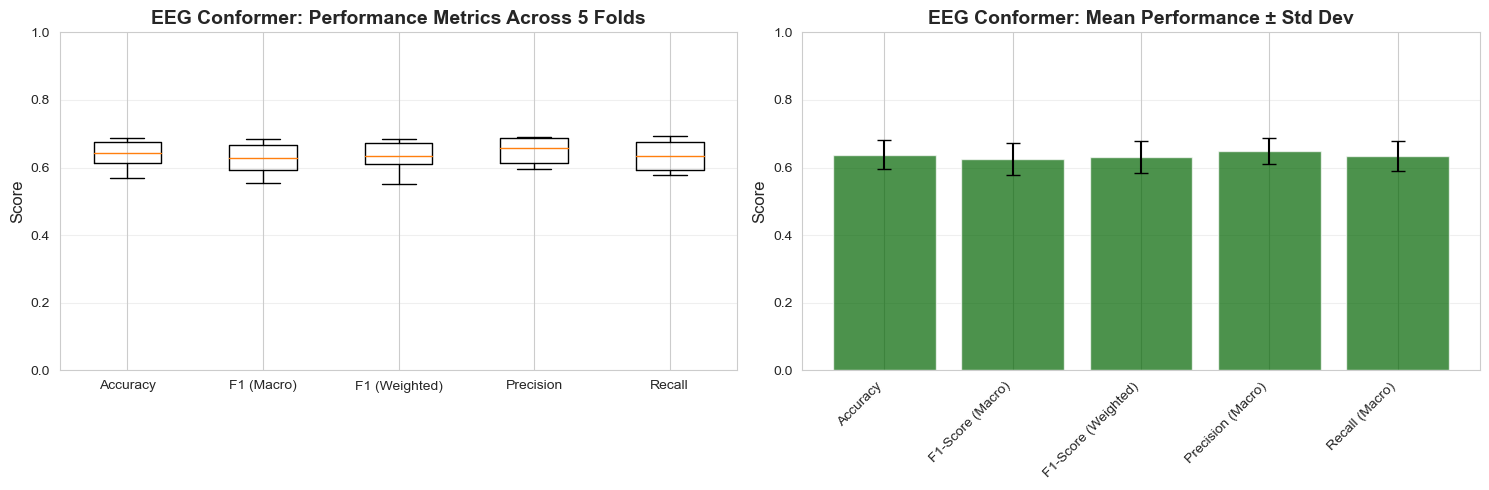

In [8]:
# Calculate mean and std for all metrics
conformer_results_summary = {
    'Metric': ['Accuracy', 'F1-Score (Macro)', 'F1-Score (Weighted)', 'Precision (Macro)', 'Recall (Macro)'],
    'Mean': [
        np.mean(conformer_fold_results['accuracy']),
        np.mean(conformer_fold_results['f1_macro']),
        np.mean(conformer_fold_results['f1_weighted']),
        np.mean(conformer_fold_results['precision_macro']),
        np.mean(conformer_fold_results['recall_macro'])
    ],
    'Std': [
        np.std(conformer_fold_results['accuracy']),
        np.std(conformer_fold_results['f1_macro']),
        np.std(conformer_fold_results['f1_weighted']),
        np.std(conformer_fold_results['precision_macro']),
        np.std(conformer_fold_results['recall_macro'])
    ]
}

df_conformer_summary = pd.DataFrame(conformer_results_summary)

print("\n" + "="*60)
print("EEG CONFORMER 5-FOLD CROSS-VALIDATION SUMMARY")
print("="*60)
print(df_conformer_summary.to_string(index=False))
print("="*60)

# Visualize results
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Box plot of metrics across folds
conformer_metrics_data = pd.DataFrame({
    'Accuracy': conformer_fold_results['accuracy'],
    'F1 (Macro)': conformer_fold_results['f1_macro'],
    'F1 (Weighted)': conformer_fold_results['f1_weighted'],
    'Precision': conformer_fold_results['precision_macro'],
    'Recall': conformer_fold_results['recall_macro']
})

axes[0].boxplot(conformer_metrics_data.values, labels=conformer_metrics_data.columns)
axes[0].set_ylabel('Score', fontsize=12)
axes[0].set_title('EEG Conformer: Performance Metrics Across 5 Folds', fontsize=14, fontweight='bold')
axes[0].grid(axis='y', alpha=0.3)
axes[0].set_ylim([0, 1])

# Plot 2: Bar plot with error bars
x_pos = np.arange(len(df_conformer_summary))
axes[1].bar(x_pos, df_conformer_summary['Mean'], yerr=df_conformer_summary['Std'], 
            capsize=5, alpha=0.7, color='darkgreen')
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(df_conformer_summary['Metric'], rotation=45, ha='right')
axes[1].set_ylabel('Score', fontsize=12)
axes[1].set_title('EEG Conformer: Mean Performance ± Std Dev', fontsize=14, fontweight='bold')
axes[1].grid(axis='y', alpha=0.3)
axes[1].set_ylim([0, 1])

plt.tight_layout()
plt.show()

## 9. Training History Visualization

In [ ]:
# Plot training history for all folds
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('EEG Conformer Training History Across 5 Folds', fontsize=16, fontweight='bold', y=1.02)

axes = axes.flatten()

for fold_num in range(n_splits):
    ax = axes[fold_num]
    
    train_history = conformer_fold_results['train_history'][fold_num]
    val_history = conformer_fold_results['val_history'][fold_num]
    
    epochs = range(1, len(train_history['accuracy']) + 1)
    
    # Plot accuracy
    ax.plot(epochs, train_history['accuracy'], 'b-', label='Train Acc', linewidth=2)
    ax.plot(epochs, val_history['accuracy'], 'r-', label='Val Acc', linewidth=2)
    
    ax.set_xlabel('Epoch', fontsize=11)
    ax.set_ylabel('Accuracy (%)', fontsize=11)
    ax.set_title(f'Fold {fold_num + 1}', fontsize=12, fontweight='bold')
    ax.legend(loc='lower right')
    ax.grid(True, alpha=0.3)
    ax.set_ylim([0, 100])

# Remove empty subplot
axes[5].axis('off')

plt.tight_layout()
plt.show()

# Plot loss curves
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('EEG Conformer Loss Curves Across 5 Folds', fontsize=16, fontweight='bold', y=1.02)

axes = axes.flatten()

for fold_num in range(n_splits):
    ax = axes[fold_num]
    
    train_history = conformer_fold_results['train_history'][fold_num]
    val_history = conformer_fold_results['val_history'][fold_num]
    
    epochs = range(1, len(train_history['loss']) + 1)
    
    # Plot loss
    ax.plot(epochs, train_history['loss'], 'b-', label='Train Loss', linewidth=2)
    ax.plot(epochs, val_history['loss'], 'r-', label='Val Loss', linewidth=2)
    
    ax.set_xlabel('Epoch', fontsize=11)
    ax.set_ylabel('Loss', fontsize=11)
    ax.set_title(f'Fold {fold_num + 1}', fontsize=12, fontweight='bold')
    ax.legend(loc='upper right')
    ax.grid(True, alpha=0.3)

# Remove empty subplot
axes[5].axis('off')

plt.tight_layout()
plt.show()

## 10. Confusion Matrix Visualization

In [ ]:
# Average confusion matrix across all folds
conformer_avg_cm = np.mean(conformer_fold_results['confusion_matrices'], axis=0)
conformer_avg_cm_normalized = conformer_avg_cm / conformer_avg_cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Raw counts
sns.heatmap(conformer_avg_cm, annot=True, fmt='.1f', cmap='Blues', 
            xticklabels=class_names, yticklabels=class_names,
            ax=axes[0], cbar_kws={'label': 'Count'})
axes[0].set_title('EEG Conformer: Average Confusion Matrix (Counts)', fontsize=14, fontweight='bold')
axes[0].set_ylabel('True Label', fontsize=12)
axes[0].set_xlabel('Predicted Label', fontsize=12)

# Plot 2: Normalized (percentages)
sns.heatmap(conformer_avg_cm_normalized, annot=True, fmt='.2%', cmap='YlOrRd', 
            xticklabels=class_names, yticklabels=class_names,
            ax=axes[1], cbar_kws={'label': 'Percentage'}, vmin=0, vmax=1)
axes[1].set_title('EEG Conformer: Average Confusion Matrix (Normalized)', fontsize=14, fontweight='bold')
axes[1].set_ylabel('True Label', fontsize=12)
axes[1].set_xlabel('Predicted Label', fontsize=12)

plt.tight_layout()
plt.show()

# Per-class accuracy
print("\nEEG Conformer Per-Class Accuracy:")
for i, class_name in enumerate(class_names):
    class_acc = conformer_avg_cm_normalized[i, i]
    print(f"  {class_name}: {class_acc:.2%}")

## 11. Save Results to CSV

In [ ]:
print("="*80)
print("SAVING EEG CONFORMER RESULTS...")
print("="*80)

# Save summary results
df_conformer_summary.to_csv('conformer_results_summary.csv', index=False)
print("✅ EEG Conformer Summary saved to: conformer_results_summary.csv")

# Save detailed fold results
conformer_fold_details = pd.DataFrame({
    'Fold': range(1, n_splits + 1),
    'Accuracy': conformer_fold_results['accuracy'],
    'F1_Macro': conformer_fold_results['f1_macro'],
    'F1_Weighted': conformer_fold_results['f1_weighted'],
    'Precision_Macro': conformer_fold_results['precision_macro'],
    'Recall_Macro': conformer_fold_results['recall_macro']
})
conformer_fold_details.to_csv('conformer_fold_details.csv', index=False)
print("✅ EEG Conformer Fold details saved to: conformer_fold_details.csv")

# Save average confusion matrix
df_conformer_cm = pd.DataFrame(conformer_avg_cm, index=class_names, columns=class_names)
df_conformer_cm.to_csv('conformer_confusion_matrix.csv')
print("✅ EEG Conformer Confusion matrix saved to: conformer_confusion_matrix.csv")

print("\n" + "="*80)
print("ALL EEG CONFORMER RESULTS SAVED SUCCESSFULLY!")
print("="*80)
print("\nSaved files:")
print("  - conformer_results_summary.csv")
print("  - conformer_fold_details.csv")
print("  - conformer_confusion_matrix.csv")
print("="*80)